# Chapter 16 — Exploratory Data Analysis and Data Quality

Exploratory data analysis (EDA) combines data contracts, missingness analysis, outlier investigation, distributions, relationships, and communication. It turns a raw dataset into a defensible analytical starting point.

## Prerequisites
Pandas, NumPy, basic plotting, and introductory statistics.

## Learning goals
- Define grain, keys, and quality rules before analyzing.
- Profile missingness, duplicates, types, ranges, and categories.
- Investigate outliers without blindly deleting them.
- Explore univariate and multivariate structure.
- Create a reproducible EDA summary and communicate caveats.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Chapter map

1. Data grain and data contracts
2. Missingness
3. Duplicates, types, and ranges
4. Outliers and robust summaries
5. Automated profiling
6. Communicating an EDA

### Data grain and data contracts
Grain states what one row represents (for example, one order line or one customer). Define primary keys, candidate keys, required fields, allowed categories, units, date ranges, and relationships. A duplicate row may be an error or a valid repeated event; uniqueness must be defined at the correct grain. Validate assumptions explicitly with assertions or schema libraries.

#### Demonstration 1 — Profile shape, types, and missingness

Run the code and inspect both the output and the assumptions behind it.

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd, numpy as np
df=pd.read_csv(DATA/"messy_sales.csv")
print("Shape:",df.shape); print(df.dtypes); display(df.isna().mean().sort_values(ascending=False).rename("missing_rate").to_frame())

Data directory: /mnt/data/python_data_analysis_book/data
Shape: (62, 11)
order_id        object
order_date      object
region          object
product         object
units          float64
unit_price     float64
discount       float64
revenue        float64
cost           float64
profit         float64
customer_id     object
dtype: object
             missing_rate
region           0.112903
units            0.096774
order_id         0.000000
order_date       0.000000
product          0.000000
unit_price       0.000000
discount         0.000000
revenue          0.000000
cost             0.000000
profit           0.000000
customer_id      0.000000


### Missingness
`isna()` identifies missing values; `notna()` identifies present values; `isna().mean()` gives missing proportion. Missing completely at random, missing at random, and missing not at random are conceptual mechanisms, not conclusions available from a missingness heatmap alone. Distinguish not applicable, not collected, unknown, and true zero. Imputation can create bias if its assumptions are wrong.

#### Demonstration 2 — Check keys and duplicates

Run the code and inspect both the output and the assumptions behind it.

In [3]:
print("Duplicate order ids:",df.order_id.duplicated().sum()); print("Duplicate full rows:",df.duplicated().sum())
display(df.loc[df.order_id.duplicated(keep=False)].sort_values("order_id").head())

Duplicate order ids: 2
Duplicate full rows: 2
   order_id  order_date region  ...      cost   profit  customer_id
0     O0042  2025-04-26    NaN  ...   4472.77  1241.69         C012
60    O0042  2025-04-26    NaN  ...   4472.77  1241.69         C012
5     O0160  2025-10-15  North  ...  10943.93  2579.05         C010
61    O0160  2025-10-15  North  ...  10943.93  2579.05         C010

[4 rows x 11 columns]


### Duplicates, types, and ranges
Use `duplicated(subset=..., keep=...)`, `drop_duplicates`, `to_datetime(errors="coerce")`, `to_numeric(errors="coerce")`, and `.astype(...)`. Validate ranges and category domains. Coercion converts invalid strings to missing; count and review these conversions rather than silently accepting them.

#### Demonstration 3 — Normalize types and categories

Run the code and inspect both the output and the assumptions behind it.

In [4]:
clean=df.copy(); clean["order_date"]=pd.to_datetime(clean.order_date,errors="coerce"); clean["units"]=pd.to_numeric(clean.units,errors="coerce"); clean["region"]=clean.region.astype("string").str.strip().str.title(); clean["product"]=clean["product"].astype("string").str.strip().str.title()
print(clean.dtypes); print("Invalid dates:",clean.order_date.isna().sum()); print("Regions:",clean.region.value_counts(dropna=False))

order_id               object
order_date     datetime64[ns]
region         string[python]
product        string[python]
units                 float64
unit_price            float64
discount              float64
revenue               float64
cost                  float64
profit                float64
customer_id            object
dtype: object
Invalid dates: 0
Regions: region
East     16
South    15
West     15
North     9
<NA>      7
Name: count, dtype: Int64


### Outliers and robust summaries
Outliers may indicate data errors, rare valid events, or a different population. Investigate source records and units. IQR fences are exploratory flags, not universal deletion rules. Compare mean with median and standard deviation with IQR/MAD. Winsorization and trimming change the estimand and should be justified and documented.

#### Demonstration 4 — Flag possible outliers

Run the code and inspect both the output and the assumptions behind it.

In [5]:
q1=clean.revenue.quantile(.25); q3=clean.revenue.quantile(.75); iqr=q3-q1; lower=q1-1.5*iqr; upper=q3+1.5*iqr
flags=clean.loc[(clean.revenue<lower)|(clean.revenue>upper),["order_id","product","units","revenue"]]
print({"lower_fence":lower,"upper_fence":upper,"flagged_rows":len(flags)}); display(flags.head())

{'lower_fence': np.float64(-66763.12500000001), 'upper_fence': np.float64(137291.15500000003), 'flagged_rows': 13}
   order_id  product  units    revenue
3     O0005  Monitor   11.0  144323.39
7     O0178   Laptop   12.0  725372.82
13    O0058   Laptop    NaN  989731.65
19    O0013  Monitor   14.0  184976.00
22    O0189   Laptop   12.0  714154.62


### Automated profiling
YData Profiling can create a rich HTML report with types, distributions, correlations, missingness, and warnings. The report is a discovery aid, not a substitute for domain review. Large datasets can generate slow or overly verbose reports; sample carefully and preserve privacy.

#### Demonstration 5 — Create an EDA visualization

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_16_exploratory_data_analysis_and_data_quality/Chapter_16_Concepts_and_Theory.ipynb:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



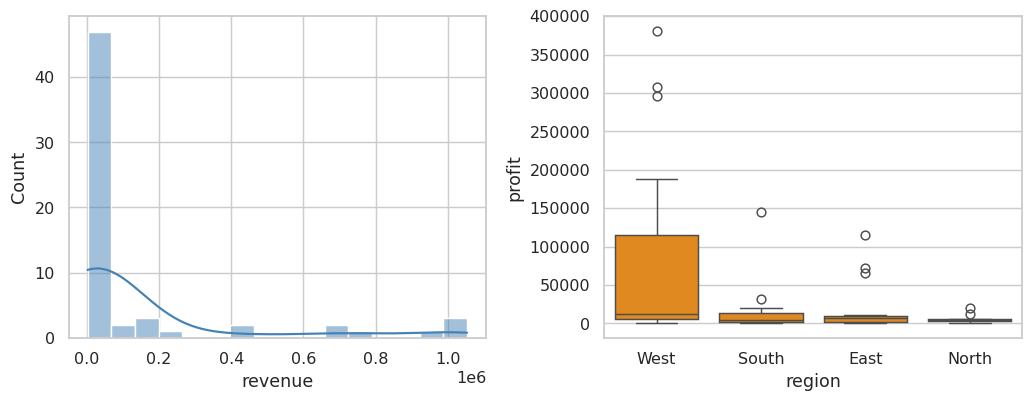

In [6]:
import seaborn as sns, matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,4)); sns.histplot(data=clean,x="revenue",kde=True,color="steelblue",ax=axes[0]); sns.boxplot(data=clean,x="region",y="profit",color="darkorange",ax=axes[1]); plt.tight_layout(); plt.show()

### Communicating an EDA
A useful handoff states the dataset source, time period, grain, row/column count, key quality findings, transformations, metrics, notable patterns, limitations, and next questions. Separate findings from hypotheses and label exploratory patterns as such.

#### Demonstration 6 — Optional automated profile

Run the code and inspect both the output and the assumptions behind it.

In [7]:
try:
 from ydata_profiling import ProfileReport
 report=ProfileReport(clean,title="Sales data quality profile",minimal=True); report.to_file("sales_profile.html"); print("Saved sales_profile.html")
except ImportError: print("Optional: pip install ydata-profiling")

Optional: pip install ydata-profiling


## Self-check

Without looking back, explain the key terms, identify the important parameters, describe at least one alternative or variation, and state one limitation of the methods covered. Then answer the exercises below.

### Review questions

- Explain one important concept from: Data grain and data contracts.
- Explain one important concept from: Missingness.
- Explain one important concept from: Duplicates, types, and ranges.
- Explain one important concept from: Outliers and robust summaries.
- Explain one important concept from: Automated profiling.